# What makes a book divisive?

**Research question 3:** holding a book's average rating fixed, which books split readers (many 1-star *and* 5-star ratings) instead of converging on a consensus? Do genre, length, publication year, series membership or the book's description explain it?

**Why it matters:** an average hides risk. A 3.8 that everyone agrees on and a 3.8 that half of readers love and half hate call for different recommendations.

**Data:** Goodreads books with at least 100 star ratings, using each book's full 1–5 star counts.

**Measuring divisiveness.** The basic measure is the standard deviation of a book's star ratings (**star sd**). On a 1–5 scale it is mechanically tied to the average: a book averaging 4.7 can't have much spread. So:
- every model includes the **average rating as a control**, and the headline result is how much *more* the other features explain;
- for description, **adjusted divisiveness** is a book's star sd minus the typical star sd for its average rating (a smooth curve fit across all books).

**Avoiding author leakage:** books by the same author (a series, say) tend to resemble each other, so the model could just recognize an author it saw in training. All cross-validation splits, including the inner splits used to tune settings, keep an author's books together (GroupKFold by author).

**Data quality:** 716 books with 100+ ratings have no author, genres, length, year or description because their detail page wasn't scraped. They carry no features and are left out; an earlier run that kept them (all grouped under one placeholder author) let a single fold collapse.

## Setup

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.inspection import partial_dependence
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import SplineTransformer, StandardScaler

from story_reception.features import book_features, book_post_features, feature_family, series_status, star_stats

SEED = 42
MIN_RATINGS = 100
CLEAN_DIR, FIG_DIR = 'data/cleaned', 'figures'

SURFACE, INK, INK2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e6e5e1'
POS, NEG, OLD = '#2a78d6', '#e34948', '#b8b7b2'      # blue = more divisive, red = more consensus
SERIES = ['#2a78d6', '#eb6834', '#1baf7a']
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'font.size': 10, 'legend.frameon': False, 'figure.dpi': 110,
})

In [2]:
raw = pd.read_csv(f'{CLEAN_DIR}/cleaned_goodreads_books.csv')
stats = star_stats(raw)
enough = stats['star count'] >= MIN_RATINGS
# Books whose detail page failed to scrape have star counts but no author, genres, pages, year or description.
has_metadata = raw['author'].notna() & raw['genres'].fillna('').ne('')
print(f'{enough.sum():,} books with {MIN_RATINGS}+ ratings; {(enough & ~has_metadata).sum():,} of them have no metadata '
      f'(detail page not scraped) and are left out')
books = raw[enough & has_metadata].reset_index(drop=True)
stats = stats[enough & has_metadata].reset_index(drop=True)
sd, avg = stats['star sd'].to_numpy(), stats['star mean'].to_numpy()
authors = books['author'].to_numpy()

X_book = book_features(books)
X_post = book_post_features(books)
data = pd.concat([X_book, X_post, stats[['star mean']], books['description'].fillna('').rename('description')], axis=1)
print(f'{len(books):,} books with {MIN_RATINGS}+ ratings, {len(set(authors)):,} authors; '
      f'star sd mean {sd.mean():.2f} (range {sd.min():.2f}–{sd.max():.2f}); '
      f'corr(sd, average) = {np.corrcoef(sd, avg)[0, 1]:.2f}')
print(f"{X_book.filter(like='genre: ').shape[1]} genre tags with 30+ books; "
      f"pages missing for {X_book['log pages'].isna().mean():.0%}, year for {X_book['publication year'].isna().mean():.0%}; "
      f"{X_book['in a series'].mean():.0%} in a series")

4,510 books with 100+ ratings; 716 of them have no metadata (detail page not scraped) and are left out
3,794 books with 100+ ratings, 2,603 authors; star sd mean 0.95 (range 0.07–1.77); corr(sd, average) = -0.68
184 genre tags with 30+ books; pages missing for 1%, year for 0%; 51% in a series


## 1. Separating divisiveness from the average

Each dot is a book. The curve is the typical star sd at each average rating (a smoothing spline fit to all books). **Adjusted divisiveness** is the vertical distance from that curve: above it, readers are more split than usual for that average.

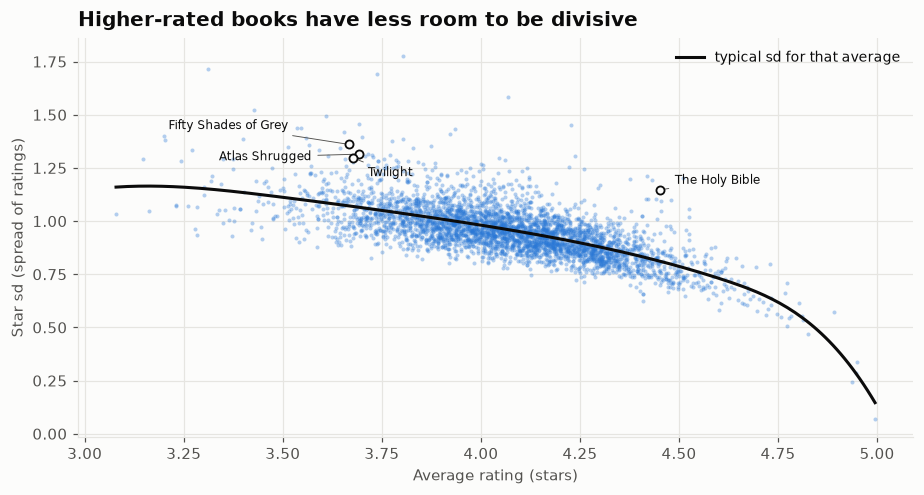

The average alone explains 48% of the variation in star sd (in-sample curve).


In [3]:
curve = make_pipeline(SplineTransformer(n_knots=6, degree=3), Ridge(alpha=1e-3)).fit(avg[:, None], sd)
expected_sd = curve.predict(avg[:, None])
adjusted = sd - expected_sd
books['star sd'], books['adjusted divisiveness'], books['average'] = sd, adjusted, avg
r2_avg_only_in_sample = r2_score(sd, expected_sd)

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.scatter(avg, sd, s=7, color=SERIES[0], alpha=0.35, linewidths=0)
grid = np.linspace(avg.min(), avg.max(), 200)
ax.plot(grid, curve.predict(grid[:, None]), color=INK, lw=2, label='typical sd for that average')
labels = {'Fifty Shades of Grey': (-118, 10), 'Atlas Shrugged': (-92, -4), 'Twilight': (10, -12),
          'The Holy Bible': (10, 4)}
for name, offset in labels.items():
    row = books[books['title'].str.startswith(name)].sort_values('ratings_count', ascending=False).head(1)
    if len(row):
        xy = (row['average'].iloc[0], row['star sd'].iloc[0])
        ax.scatter(*xy, s=28, facecolor=SURFACE, edgecolor=INK, linewidth=1.2, zorder=4)
        ax.annotate(row['title'].iloc[0].split(':')[0][:28], xy, fontsize=8, xytext=offset,
                    textcoords='offset points', color=INK, arrowprops={'arrowstyle': '-', 'color': INK2, 'lw': 0.6})
ax.set_xlabel('Average rating (stars)')
ax.set_ylabel('Star sd (spread of ratings)')
ax.set_title('Higher-rated books have less room to be divisive', pad=8)
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()
print(f'The average alone explains {r2_avg_only_in_sample:.0%} of the variation in star sd (in-sample curve).')

In [4]:
wide = books[books['ratings_count'] >= 100_000]
cols = ['title', 'author', 'publication_year', 'ratings_count', 'average', 'star sd', 'adjusted divisiveness']
fmt = {'ratings_count': '{:,.0f}', 'average': '{:.2f}', 'star sd': '{:.2f}', 'adjusted divisiveness': '{:+.2f}',
       'publication_year': '{:.0f}'}
print(f'Among {len(wide):,} widely read books (100,000+ ratings), most divisive for their average:')
display(wide.nlargest(10, 'adjusted divisiveness')[cols].style.format(fmt).hide(axis='index'))
print('...and most consensus:')
display(wide.nsmallest(10, 'adjusted divisiveness')[cols].style.format(fmt).hide(axis='index'))

Among 1,115 widely read books (100,000+ ratings), most divisive for their average:


title,author,publication_year,ratings_count,average,star sd,adjusted divisiveness
The Holy Bible: King James Version,Anonymous,2008,"322,822",4.45,1.15,+0.33
Fifty Shades of Grey,E.L. James,2011,"2,893,045",3.67,1.36,+0.29
Atlas Shrugged,Ayn Rand,1999,"409,308",3.69,1.31,+0.25
The Story of Art,E.H. Gombrich,1967,"469,675",3.96,1.23,+0.24
The Secret,Rhonda Byrne,2006,"539,804",3.74,1.28,+0.23
Twilight,Stephenie Meyer,2006,"7,398,289",3.68,1.30,+0.23
The Twilight Saga,Stephenie Meyer,2008,"123,748",3.94,1.23,+0.23
Den of Vipers,K.A. Knight,2020,"239,246",3.66,1.29,+0.22
Ulysses,James Joyce,1990,"139,570",3.76,1.26,+0.22
Understanding Comics: The Invisible Art,Scott McCloud,1993,"133,037",4.00,1.19,+0.21


...and most consensus:


title,author,publication_year,ratings_count,average,star sd,adjusted divisiveness
The Club,Ellery Lloyd,2022,"128,264",3.28,0.96,-0.19
In a Holidaze,Christina Lauren,2020,"253,076",3.65,0.89,-0.19
Killer Instinct,Jennifer Lynn Barnes,2014,"244,086",4.26,0.71,-0.18
Hercule Poirot's Christmas,Agatha Christie,2001,"110,984",3.98,0.80,-0.18
Listen for the Lie,Amy Tintera,2024,"575,603",4.07,0.78,-0.18
"My Sister, the Serial Killer",Oyinkan Braithwaite,2018,"364,258",3.63,0.90,-0.18
What Lies in the Woods,Kate Alice Marshall,2023,"208,708",3.94,0.82,-0.18
Emily Wilde’s Map of the Otherlands,Heather Fawcett,2024,"108,852",4.24,0.72,-0.18
The Paris Apartment,Lucy Foley,2022,"736,784",3.64,0.90,-0.17
Vera Wong's Unsolicited Advice for Murderers,Jesse Q. Sutanto,2023,"215,693",4.02,0.80,-0.17


**The average rating explains about half of star spread on its own** (48% in-sample, 47% on held-out authors), so adjusting for it matters. Books averaging 4.5+ have little room to split readers; below 4.0 the typical spread levels off around 1.1–1.2 stars.

**The most divisive widely read books** (100,000+ ratings) are ones people seem to argue about for reasons beyond craft: scripture (*The Holy Bible*), erotic or dark romance (*Fifty Shades of Grey*, *Den of Vipers*), ideology (*Atlas Shrugged*), self-help (*The Secret*), *Twilight*, and difficult classics (*Ulysses*). **The most consensus** books are mostly recent mysteries and thrillers (*The Club*, *The Paris Apartment*, *Listen for the Lie*, an Agatha Christie), plus a romcom and a cozy fantasy. Their averages vary (3.3–4.3), but readers agree with each other.

## 2. What goes with divisiveness

Average adjusted divisiveness by group, with 95% intervals. Blue: more divisive than usual for their average rating. Red: more consensus. Gray: interval includes zero.

Intervals are **clustered by author**: books by the same author resemble each other, so a genre dominated by a few prolific authors carries less independent evidence than its book count suggests. The standard error comes from per-author sums of deviations (the usual cluster-robust formula), not from treating every book as independent.

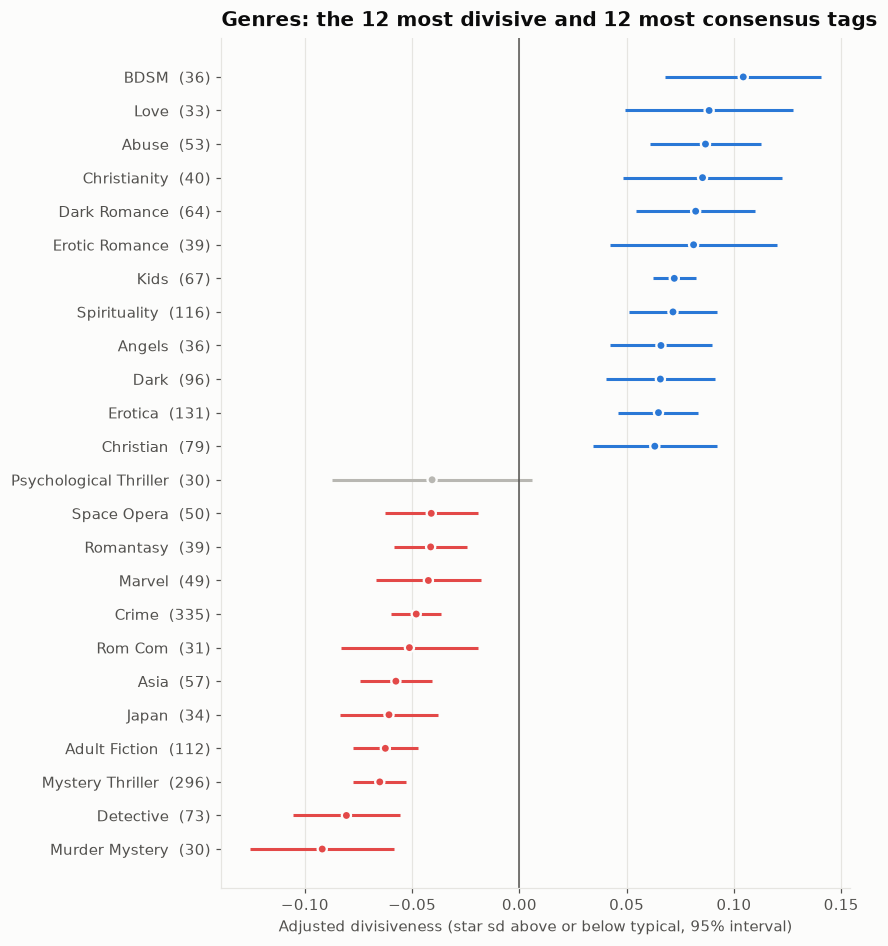

In [5]:
def group_means(labels, min_n=30, values=None, clusters=None):
    # Mean per group with an author-clustered standard error. labels, values and clusters align row by row.
    d = pd.DataFrame({'group': labels, 'y': adjusted if values is None else values,
                      'author': authors if clusters is None else clusters}).dropna(subset=['group'])
    rows = {}
    for name, grp in d.groupby('group'):
        n = len(grp)
        if n < min_n:
            continue
        mean = grp['y'].mean()
        per_author = (grp['y'] - mean).groupby(grp['author']).sum()
        c = len(per_author)
        se = np.sqrt((per_author ** 2).sum()) / n * np.sqrt(c / (c - 1)) if c > 1 else np.nan
        rows[name] = {'mean': mean, 'se': se, 'count': n, 'authors': c}
    return pd.DataFrame(rows).T.astype({'count': int, 'authors': int})

def dot_panel(ax, g, title):
    lo, hi = g['mean'] - 1.96 * g['se'], g['mean'] + 1.96 * g['se']
    colors = np.where(lo > 0, POS, np.where(hi < 0, NEG, OLD))
    y = np.arange(len(g))[::-1]
    ax.hlines(y, lo, hi, color=colors, lw=2)
    ax.scatter(g['mean'], y, color=colors, s=36, zorder=3, edgecolor=SURFACE, linewidth=1.5)
    ax.set_yticks(y, [f'{k}  ({int(n):,})' for k, n in zip(g.index, g['count'])])
    ax.axvline(0, color=INK2, lw=1)
    ax.set_title(title, fontsize=11)
    ax.grid(axis='y', visible=False)

# genres: one row per (book, tag), so each book counts once in every tag it carries
genre_cols = list(X_book.filter(like='genre: ').columns)
book_idx, tag_idx = np.nonzero(X_book[genre_cols].to_numpy())
genre_g = group_means(np.array([c.replace('genre: ', '') for c in genre_cols])[tag_idx],
                      values=adjusted[book_idx], clusters=authors[book_idx])
genre_show = pd.concat([genre_g.nlargest(12, 'mean'), genre_g.nsmallest(12, 'mean')]).drop_duplicates()
genre_show = genre_show.sort_values('mean', ascending=False)

fig, ax = plt.subplots(figsize=(8, 0.3 * len(genre_show) + 1.5))
dot_panel(ax, genre_show, '')
ax.set_title('Genres: the 12 most divisive and 12 most consensus tags', pad=8)
ax.set_xlabel('Adjusted divisiveness (star sd above or below typical, 95% interval)')
plt.tight_layout()
fig.savefig(f'{FIG_DIR}/divisive-genres.png', dpi=160, bbox_inches='tight')
plt.show()

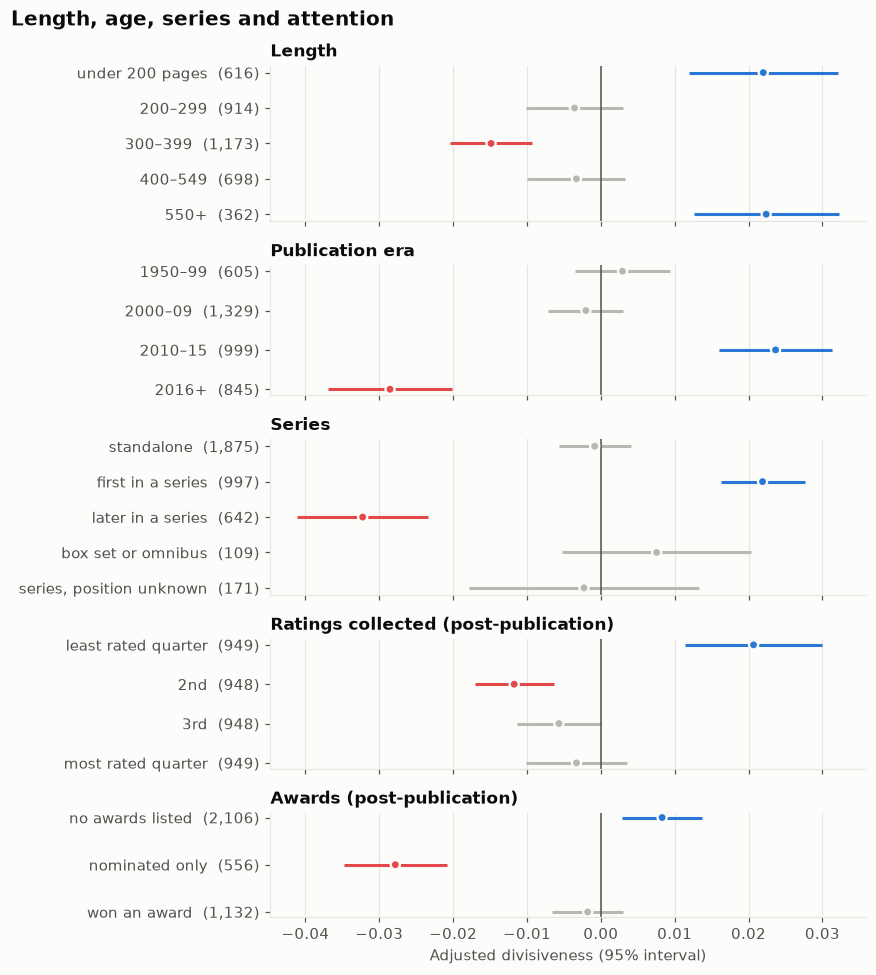

In [6]:
pages = pd.to_numeric(books['num_pages'], errors='coerce').where(lambda p: p > 0)   # raw counts: no log round trip
length = pd.cut(pages, [0, 199, 299, 399, 549, 100_000], labels=['under 200 pages', '200–299', '300–399', '400–549', '550+'])
year = X_book['publication year']
era = pd.cut(year, [0, 1949, 1999, 2009, 2015, 2100], labels=['before 1950', '1950–99', '2000–09', '2010–15', '2016+'])
series = series_status(books)
popularity = pd.qcut(X_post['log ratings count'], 4, labels=['least rated quarter', '2nd', '3rd', 'most rated quarter'])
awards = np.where(X_post['award wins'] > 0, 'won an award', np.where(X_post['award nominations'] > 0,
                                                                      'nominated only', 'no awards listed'))

def ordered(g, order):
    return g.loc[[o for o in order if o in g.index]]

panels = [('Length', ordered(group_means(length.astype(str).where(length.notna())), list(length.cat.categories))),
          ('Publication era', ordered(group_means(era.astype(str).where(era.notna())), list(era.cat.categories))),
          ('Series', ordered(group_means(series), ['standalone', 'first in a series', 'later in a series',
                                                   'box set or omnibus', 'series, position unknown'])),
          ('Ratings collected (post-publication)', ordered(group_means(popularity.astype(str)),
                                                           list(popularity.cat.categories))),
          ('Awards (post-publication)', ordered(group_means(awards), ['no awards listed', 'nominated only',
                                                                       'won an award']))]
fig, axes = plt.subplots(len(panels), 1, figsize=(8, 9), sharex=True,
                         gridspec_kw={'height_ratios': [len(p[1]) + 1 for p in panels]})
for ax, (title, g) in zip(axes, panels):
    dot_panel(ax, g, title)
axes[-1].set_xlabel('Adjusted divisiveness (95% interval)')
fig.suptitle('Length, age, series and attention', x=0.01, ha='left', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Books that touch values divide readers; books that follow a genre's rules unite them.**

- **Most divisive tags:** sexual content (BDSM, Erotica, Erotic and Dark Romance), religion (Christianity, Spirituality, Angels), Abuse, and children's books (Kids, Storytime). Plausibly, these are subjects where readers judge the content, not just the execution.
- **Most consensus tags:** mysteries and crime (Murder Mystery, Detective, Mystery Thriller, Crime), plus Rom Com, Romantasy, Space Opera and Marvel. Readers who pick these probably know what they're getting.
- **Length is U-shaped:** books under 200 pages and over 550 are more divisive; 300–399 pages is the most consensus.
- **Series show self-selection:** first books are more divisive than standalones (+0.022) and later volumes the least divisive (−0.032), likely because readers who disliked book one mostly don't go on to rate book three. Box sets and omnibuses (positions like "1-4") and series books with no listed position are kept separate; neither differs from zero.
- **Era:** books from 2010–15 are the most divisive and those from 2016 on the least; recent books may so far have been rated mostly by their target readers.
- **Attention (post-publication):** the least-rated quarter is the most divisive, and books nominated for (but not winning) an award are less divisive than books with none listed.

The effects are real but modest: group differences are a few hundredths of a star of spread, against a typical spread of 0.95. Intervals are clustered by author, which widens them by up to 1.6× for tags dominated by a few prolific authors (Detective, Murder Mystery); every tag in the chart still differs from zero except Psychological Thriller.

## 3. Predicting divisiveness

Target: **star sd**. Every model except the baseline includes the average rating (through a spline for the linear models), so the question is what each feature group adds. Two numbers per model:
- **R²:** share of star-sd variance explained on held-out authors.
- **Beyond the average:** the share of the variance left after the average-only model that the extra features explain, 1 − (1 − R²) / (1 − R²<sub>average only</sub>).

Outer CV: 5-fold GroupKFold by author, shuffled and repeated with two seeds (10 folds). Settings are tuned by an inner 3-fold GroupKFold (also by author) within each training fold.

In [7]:
GENRE = genre_cols
META = list(X_book.columns)
POST = list(X_post.columns)
AVG = ['star mean']

def outer_splits():
    for seed in (SEED, SEED + 1):
        yield from GroupKFold(n_splits=5, shuffle=True, random_state=seed).split(data, sd, authors)

inner = GroupKFold(n_splits=3, shuffle=True, random_state=SEED)

def fit_model(model, X, y, groups):
    # GridSearchCV needs the author groups for its inner GroupKFold; plain pipelines don't take them
    return model.fit(X, y, groups=groups) if isinstance(model, GridSearchCV) else model.fit(X, y)

def ridge(cols, text=False):
    parts = [('avg', SplineTransformer(n_knots=6, degree=3), AVG)]
    if cols:
        parts.append(('num', make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler()), cols))
    if text:
        parts.append(('text', TfidfVectorizer(min_df=5, max_features=8000, ngram_range=(1, 2), stop_words='english',
                                              sublinear_tf=True), 'description'))
    return GridSearchCV(make_pipeline(ColumnTransformer(parts), Ridge()),
                        {'ridge__alpha': [0.3, 1, 3, 10, 30, 100]}, cv=inner, scoring='r2')

def forest(cols):
    return make_pipeline(ColumnTransformer([('num', SimpleImputer(strategy='median', add_indicator=True), AVG + cols)]),
                         RandomForestRegressor(n_estimators=400, min_samples_leaf=5, max_features=0.33,
                                               n_jobs=-1, random_state=SEED))

def boosting(cols):
    pipe = make_pipeline(ColumnTransformer([('num', 'passthrough', AVG + cols)]),
                         HistGradientBoostingRegressor(learning_rate=0.05, l2_regularization=1.0, min_samples_leaf=20,
                                                       early_stopping=False, random_state=SEED))
    # No built-in early stopping: its random validation split ignores authors. The number of rounds is
    # tuned by the author-grouped inner CV instead.
    grid = {'histgradientboostingregressor__max_iter': [100, 300],
            'histgradientboostingregressor__max_leaf_nodes': [7, 15]}
    return GridSearchCV(pipe, grid, cv=inner, scoring='r2')

MODELS = {
    'Mean baseline':                          (DummyRegressor(), 'none'),
    'Average rating only':                    (ridge([]), 'control'),
    '+ genre (Ridge)':                        (ridge(GENRE), 'at publication'),
    '+ all metadata (Ridge)':                 (ridge(META), 'at publication'),
    '+ all metadata (random forest)':         (forest(META), 'at publication'),
    '+ all metadata (gradient boosting)':     (boosting(META), 'at publication'),
    '+ metadata + description TF-IDF (Ridge)': (ridge(META, text=True), 'at publication'),
    '+ metadata + popularity, awards (boosting)': (boosting(META + POST), 'post-publication'),
}

def cv_scores(model, target):
    scores = []
    for tr, te in outer_splits():
        m = fit_model(clone(model), data.iloc[tr], target[tr], authors[tr])
        scores.append(r2_score(target[te], m.predict(data.iloc[te])))
    return np.array(scores)

results = {}
for name, (model, group) in MODELS.items():
    start = time.time()
    results[name] = (cv_scores(model, sd), group)
    print(f'{name:45s} R² {results[name][0].mean():.3f} ± {results[name][0].std():.3f}  ({time.time() - start:.0f}s)')

base = results['Average rating only'][0].mean()
table = pd.DataFrame([{'model': n, 'features known': g, 'R² mean': s.mean(), 'R² sd': s.std(),
                       'beyond the average': 1 - (1 - s.mean()) / (1 - base) if g not in ('none', 'control') else np.nan}
                      for n, (s, g) in results.items()]).set_index('model')
display(table.style.format({'R² mean': '{:.3f}', 'R² sd': '{:.3f}', 'beyond the average': '{:.0%}'}, na_rep='-'))

Mean baseline                                 R² -0.002 ± 0.002  (0s)


Average rating only                           R² 0.474 ± 0.023  (2s)


+ genre (Ridge)                               R² 0.594 ± 0.031  (6s)


+ all metadata (Ridge)                        R² 0.624 ± 0.029  (6s)


+ all metadata (random forest)                R² 0.627 ± 0.016  (6s)


+ all metadata (gradient boosting)            R² 0.652 ± 0.025  (84s)


+ metadata + description TF-IDF (Ridge)       R² 0.608 ± 0.028  (124s)


+ metadata + popularity, awards (boosting)    R² 0.681 ± 0.024  (92s)


,features known,R² mean,R² sd,beyond the average
model,,,,
Mean baseline,none,-0.002,0.002,-
Average rating only,control,0.474,0.023,-
+ genre (Ridge),at publication,0.594,0.031,23%
+ all metadata (Ridge),at publication,0.624,0.029,29%
+ all metadata (random forest),at publication,0.627,0.016,29%
+ all metadata (gradient boosting),at publication,0.652,0.025,34%
+ metadata + description TF-IDF (Ridge),at publication,0.608,0.028,25%
"+ metadata + popularity, awards (boosting)",post-publication,0.681,0.024,39%


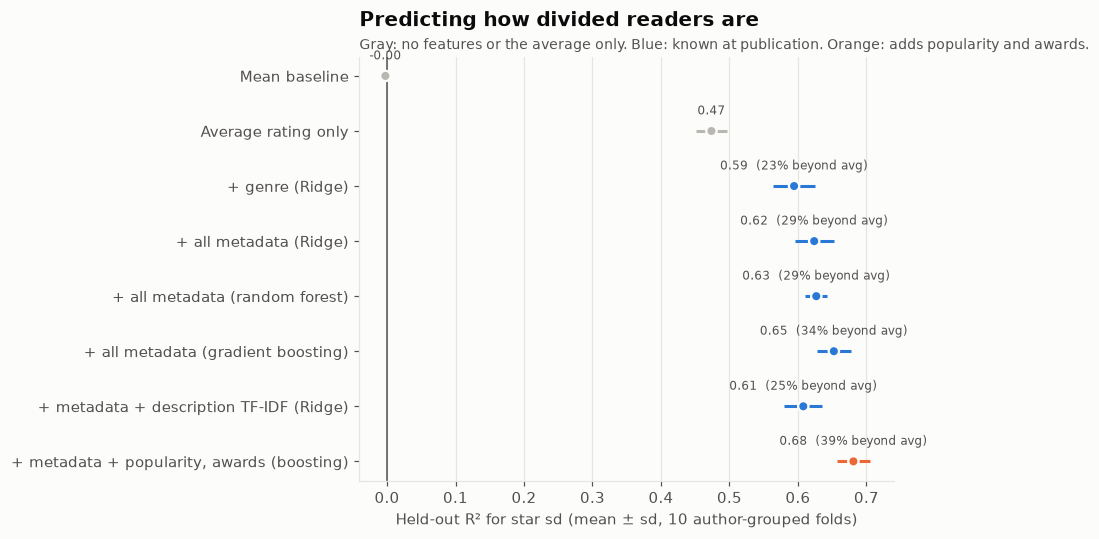

In [8]:
order = table.index[::-1]
colors = [OLD if g in ('none', 'control') else (SERIES[1] if g == 'post-publication' else SERIES[0])
          for g in table.loc[order, 'features known']]
fig, ax = plt.subplots(figsize=(8.5, 0.45 * len(order) + 1.4))
y = np.arange(len(order))
ax.hlines(y, table.loc[order, 'R² mean'] - table.loc[order, 'R² sd'], table.loc[order, 'R² mean'] + table.loc[order, 'R² sd'],
          color=colors, lw=2)
ax.scatter(table.loc[order, 'R² mean'], y, color=colors, s=46, zorder=3, edgecolor=SURFACE, linewidth=1.5)
for yv, v, b in zip(y, table.loc[order, 'R² mean'], table.loc[order, 'beyond the average']):
    label = f'{v:.2f}' + ('' if pd.isna(b) else f'  ({b:.0%} beyond avg)')
    ax.text(v, yv + 0.3, label, ha='center', fontsize=8, color=INK2)
ax.set_yticks(y, order)
ax.axvline(0, color=INK2, lw=1)
ax.grid(axis='y', visible=False)
ax.set_xlabel('Held-out R² for star sd (mean ± sd, 10 author-grouped folds)')
ax.set_title('Predicting how divided readers are', pad=20)
ax.text(0, 1.01, 'Gray: no features or the average only. Blue: known at publication. Orange: adds popularity and awards.',
        transform=ax.transAxes, color=INK2, fontsize=9, va='bottom')
plt.tight_layout()
fig.savefig(f'{FIG_DIR}/divisive-models.png', dpi=160, bbox_inches='tight')
plt.show()

**Metadata known at publication explains about a third (34%) of the divisiveness that the average rating doesn't.**

| Model (held-out authors) | R² | Beyond the average |
|---|---|---|
| Average rating only | 0.47 | – |
| + genre tags (Ridge) | 0.59 | 23% |
| + all metadata (Ridge) | 0.62 | 29% |
| + all metadata (random forest) | 0.63 | 29% |
| **+ all metadata (gradient boosting)** | **0.65** | **34%** |
| + metadata + description TF-IDF (Ridge) | 0.61 | 25% |
| + popularity and awards (boosting, post-publication) | 0.68 | 39% |

- **Genre does most of the work.** Reader tags alone account for 23 of the 34 points.
- **Boosting beats the linear models** (34% vs. 29%). Tag combinations and the U-shaped length effect are non-linear.
- **The publisher's description hurts** (25% vs. 29% without it). Like film synopses, it likely describes subject matter that the tags already encode.
- **Boosting's number of rounds is tuned by the author-grouped inner CV,** not by scikit-learn's built-in early stopping, whose random validation split would mix authors.
- **The results are stable:** every model's R² varies by ±0.03 or less across the 10 author-grouped folds.

## 4. What the models rely on

Shuffle importance by feature family for the best at-publication model: the drop in held-out R² when a family's columns are shuffled together. Five author-grouped folds, five shuffles each.

Best at-publication model: + all metadata (gradient boosting)


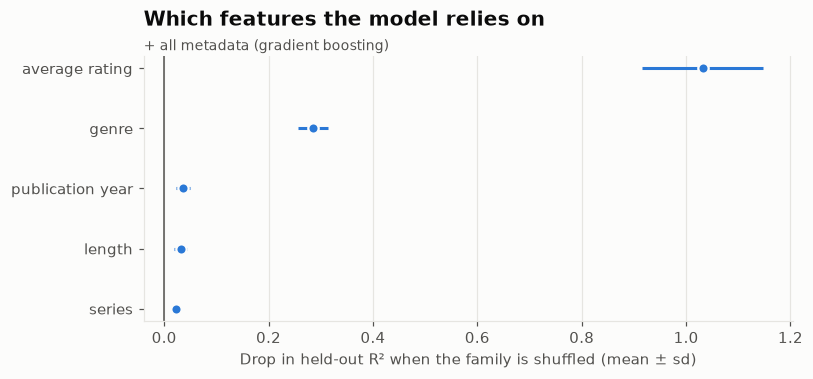

In [9]:
at_pub = table[table['features known'] == 'at publication']
best_name = at_pub['R² mean'].idxmax()
best = MODELS[best_name][0]
print('Best at-publication model:', best_name)

def model_columns(model):
    pipe = model.estimator if isinstance(model, GridSearchCV) else model
    ct = next(step for step in pipe.named_steps.values() if isinstance(step, ColumnTransformer))
    cols = []
    for _, _, c in ct.transformers:
        cols += [c] if isinstance(c, str) else list(c)
    return cols

families = {}
for c in model_columns(best):
    families.setdefault('description' if c == 'description' else feature_family(c), []).append(c)

rng = np.random.default_rng(SEED)
drops = {f: [] for f in families}
for tr, te in GroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(data, sd, authors):
    m = fit_model(clone(best), data.iloc[tr], sd[tr], authors[tr])
    base_r2 = r2_score(sd[te], m.predict(data.iloc[te]))
    for fam, cols in families.items():
        for _ in range(5):
            shuffled = data.iloc[te].copy()
            shuffled[cols] = shuffled[cols].to_numpy()[rng.permutation(len(te))]
            drops[fam].append(base_r2 - r2_score(sd[te], m.predict(shuffled)))
imp = pd.DataFrame({'R² drop': {f: np.mean(v) for f, v in drops.items()},
                    'sd': {f: np.std(v) for f, v in drops.items()}}).sort_values('R² drop')
fig, ax = plt.subplots(figsize=(7.5, 0.45 * len(imp) + 1.3))
y = np.arange(len(imp))
ax.hlines(y, imp['R² drop'] - imp['sd'], imp['R² drop'] + imp['sd'], color=SERIES[0], lw=2)
ax.scatter(imp['R² drop'], y, color=SERIES[0], s=46, zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.set_yticks(y, imp.index)
ax.axvline(0, color=INK2, lw=1)
ax.grid(axis='y', visible=False)
ax.set_xlabel('Drop in held-out R² when the family is shuffled (mean ± sd)')
ax.set_title('Which features the model relies on', pad=20)
ax.text(0, 1.01, best_name, transform=ax.transAxes, color=INK2, fontsize=9, va='bottom')
plt.tight_layout()
plt.show()

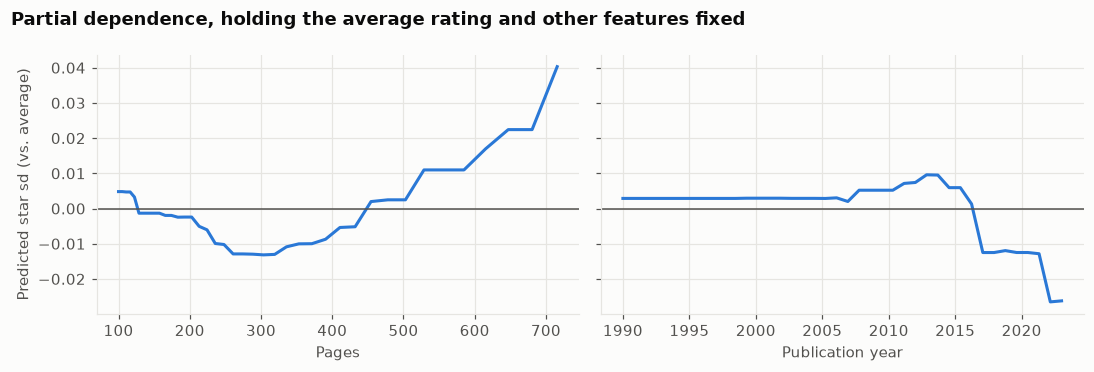

In [10]:
# Length and publication year, holding the rest fixed (gradient-boosting metadata model, all books)
gb = fit_model(clone(MODELS['+ all metadata (gradient boosting)'][0]), data, sd, authors)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, col, xlabel, transform in [(axes[0], 'log pages', 'Pages', np.exp),
                                   (axes[1], 'publication year', 'Publication year', lambda v: v)]:
    pdp = partial_dependence(gb.best_estimator_, data, [col], grid_resolution=40, percentiles=(0.05, 0.95))
    ax.plot(transform(pdp['grid_values'][0]), pdp['average'][0] - pdp['average'][0].mean(), color=SERIES[0], lw=2)
    ax.axhline(0, color=INK2, lw=1)
    ax.set_xlabel(xlabel)
axes[0].set_ylabel('Predicted star sd (vs. average)')
fig.suptitle('Partial dependence, holding the average rating and other features fixed', x=0.01, ha='left',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**After the average rating, genre is the feature family the model leans on most.** Shuffling genre costs about 0.29 of held-out R², far more than publication year (0.03), length (0.03) or series (0.02). The average rating itself costs about 1.03: shuffling it breaks the mechanical link the model depends on.

**Partial dependence** matches the group averages: predicted spread dips for 250–300-page books and climbs steadily past 450 pages, and books published after 2016 are predicted to be less divisive.

## 5. Robustness: a second measure of divisiveness

Star sd treats a 2-star and a 4-star rating as equally far from a 3. A blunter measure is the **share of 1- and 2-star ratings**, again with the average as a control. The same ladder, refit on that target:

In [11]:
low = stats['share 1-2 stars'].to_numpy()
rob = {}
for name in ['Average rating only', '+ all metadata (Ridge)', '+ all metadata (gradient boosting)',
             '+ metadata + description TF-IDF (Ridge)']:
    rob[name] = cv_scores(MODELS[name][0], low)
rob_base = rob['Average rating only'].mean()
display(pd.DataFrame([{'model': n, 'R² mean': s.mean(), 'R² sd': s.std(),
                       'beyond the average': np.nan if n == 'Average rating only' else 1 - (1 - s.mean()) / (1 - rob_base)}
                      for n, s in rob.items()]).set_index('model')
        .style.format({'R² mean': '{:.3f}', 'R² sd': '{:.3f}', 'beyond the average': '{:.0%}'}, na_rep='-'))
print(f'corr(star sd, share 1-2 stars) = {np.corrcoef(sd, low)[0, 1]:.2f}')

,R² mean,R² sd,beyond the average
model,,,
Average rating only,0.720,0.024,-
+ all metadata (Ridge),0.795,0.011,27%
+ all metadata (gradient boosting),0.808,0.012,32%
+ metadata + description TF-IDF (Ridge),0.782,0.008,22%


corr(star sd, share 1-2 stars) = 0.89


**The findings don't depend on the measure.** The share of 1–2 star ratings tracks star sd closely (correlation 0.89). With it as the target, metadata again explains about a third of what the average leaves (32% for gradient boosting, 27% for Ridge), and the description again doesn't help (22%).

## Conclusion

**What makes a book divisive:** mostly, it seems, subject matter that invites moral judgment (sex, religion, abuse), more than anything about form. Erotic and dark romance, Christian and spiritual books, and books about abuse split readers more than their averages predict. Mysteries, crime fiction and other books with clear genre conventions unite them. Very short and very long books are more divisive, and so are first books in a series, while later volumes are likely rated mostly by readers who liked the first.

**How predictable it is:** the average rating explains 47% of star spread on held-out authors. Metadata known at publication explains about a third (34%) of what's left, mostly through genre tags; popularity and awards push that to 39%. The book description adds nothing.

**Method notes:** 3,794 books with 100+ ratings and full metadata, from 2,603 authors; GroupKFold by author for both the outer and inner (tuning) splits; the same results with a second divisiveness measure. Problems fixed along the way: an ungrouped inner CV and ungrouped early stopping that could reward memorizing authors; 716 books with no scraped metadata that had been pooled under one placeholder author; box sets ("1-4") miscounted as first books in a series; and group intervals that ignored author clustering.

**Limits:** Goodreads tags come from readers, so "Dark Romance" partly reflects how readers already reacted. The book list comes from popular Listopia lists, which skews toward genre fiction. These are associations, not causal effects.